# **Mastercard Data Quest:** Identifying hidden commercial activity based on individuals' transaction data
## Team: Outsiders
### Members: Urazova Alina, Kemelkhan Alikhan, Rudkovskaya Arina and Slepokurova Violeta

#  Navigation
0. [Import Libraries and Initial Setup](#Import-Libraries-and-Initial-Setup)
1. [Importing Data](#1.-Importing-Data)
2. [General Data Overview and Converting Data Types](#2.-General-Data-Overview-and-Converting-Data-Types)
3. [Data Quality Checks](#3.-Data-Quality-Checks)
4. [Hypothesis Preparation](#4.-Hypothesis-Preparation)
5. [Hypothesis Testing](#5.-Hypothesis-Testing)
6. [Combined Hypothesis Summary](#6.-Combined-Hypothesis-Summary)
7. [Selection of Clean Ordinary Consumers](#7.-Selection-of-Clean-Ordinary-Consumers)
8. [Preparation of Reliable Training Dataset](#8.-Preparation-of-Reliable-Training-Dataset)
9. [Model Comparison](#9.-Model-Comparison)
10. [Final Model Selection & Probability Threshold Review](#10.-Final-Model-Selection-&-Probability-Threshold-Review)
11. [Model-Based Scoring of Uncertain Consumers](#11.-Model-Based-Scoring-of-Uncertain-Consumers)
12. [Final Binary Prediction Summary](#12.-Final-Binary-Prediction-Summary)
13. [Final Output](#13.-Final-Output)
14. [Additional INFO for Analysis: Business-Segmentation](#Additional-INFO-for-Analysis:-Business--Segmentation)

# Import Libraries and Initial Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from scipy.stats import chi2_contingency

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV, train_test_split


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

BaseDir=Path(".")

# 1. Importing Data

In [2]:
MerRef=pd.read_parquet(BaseDir/'merchants_reference.parquet')
BusCard=pd.read_parquet(BaseDir/'business_cards_MDQ.parquet')
ConCard=pd.read_parquet(BaseDir/'consumer_cards_MDQ.parquet')

### Three datasets were loaded for the analysis: the merchant reference table, business card transactions, and consumer card transactions. The merchant reference dataset contains information about merchants, including merchant IDs, MCC codes, merchant names, countries, and recurring payment capability. The business and consumer card datasets contain transaction-level data that will be used for behavioral analysis, feature engineering, and model training.

# 2. General Data Overview and Converting Data Types


In this step, we make General overview of loaded datasets:

In [3]:
overview=pd.DataFrame({
    'dataset': ['merchant_reference', 'known_business_transactions', 'consumer_transactions'],
    'rows': [len(MerRef), len(BusCard), len(ConCard)],
    'columns': [MerRef.shape[1], BusCard.shape[1], ConCard.shape[1]],
    'unique_cards': [np.nan, BusCard['card_number'].nunique(), ConCard['card_number'].nunique()],
})
overview

,dataset,rows,columns,unique_cards
0,merchant_reference,2165,5,NaN
1,known_business_transactions,2997593,12,"25,000.0000"
2,consumer_transactions,9832487,12,"80,000.0000"


In [4]:
display(MerRef.head())
display(BusCard.head())
display(ConCard.head())

,merchant_id,merchant_name,mcc,merchant_country,recurring_capable
0,MER_000000,Google Ads,7311,Ireland,True
1,MER_000001,Meta Ads,7311,Ireland,True
2,MER_000002,TikTok Ads,7311,Singapore,True
3,MER_000003,Yandex Direct,7311,Russia,True
4,MER_000004,LinkedIn Ads,7311,Ireland,True


,transaction_date,transaction_timestamp,transaction_amount_kzt,mcc,merchant_id,channel,bank_name,country,card_number,card_tier,tokenized,is_recurring
0,2025-10-01,2025-10-01 00:00:00,180976,7372,MER_000007,online,Kaspi,US,5228592291438845,Business,False,True
1,2025-10-01,2025-10-01 00:00:00,153206,7372,MER_000006,online,Home Credit Bank,US,5201495142193372,Business,False,True
2,2025-10-01,2025-10-01 00:00:00,197106,7372,MER_000007,online,Home Credit Bank,US,5201492177677288,Business,False,True
3,2025-10-01,2025-10-01 00:01:00,189598,7372,MER_000008,online,Kaspi,US,5176513443697635,Business,False,True
4,2025-10-01,2025-10-01 00:03:00,700571,7311,MER_000003,online,Halyk,Russia,5100611967455520,Business,False,True


,transaction_date,transaction_timestamp,transaction_amount_kzt,mcc,merchant_id,channel,bank_name,country,card_number,card_tier,tokenized,is_recurring
0,2025-10-01,2025-10-01 00:04:00,4788,4814,MER_000064,online,Alatau City Bank,Kazakhstan,5263907968824596,Standard,False,True
1,2025-10-01,2025-10-01 00:10:00,5240,4814,MER_000063,online,Bank RBK,Kazakhstan,5119023663984986,Standard,False,True
2,2025-10-01,2025-10-01 00:12:00,4576,4814,MER_000066,online,Kaspi,Kazakhstan,5228590878155154,Standard,False,True
3,2025-10-01,2025-10-01 00:37:00,6078,4814,MER_000063,online,Home Credit Bank,Kazakhstan,5338472125333693,Standard,False,True
4,2025-10-01,2025-10-01 00:37:00,6042,4814,MER_000065,online,Kaspi,Kazakhstan,5531514712394557,Affluent,False,True


We also convert MCC codes to string format and transform date columns into datetime format for further time-based analysis:

In [5]:
MerRef['mcc']=MerRef['mcc'].astype('string')
for df in [BusCard, ConCard]:
    df['mcc']=df['mcc'].astype('string')
    df['transaction_date'] = pd.to_datetime(df['transaction_date'])
    df['transaction_timestamp'] = pd.to_datetime(df['transaction_timestamp'])

### The initial data overview confirms that all three datasets were loaded correctly. The merchant reference table contains merchant-level information, while the business and consumer datasets contain transaction-level records with the same structure. Business transactions cover 25,000 unique cards, and consumer transactions cover 80,000 unique cards. MCC codes and date fields were converted to appropriate formats for further behavioral analysis and feature engineering.

# 3. Data Quality Checks

In this step, we check for duplicates and zero values:

In [6]:
QualitySummary=pd.DataFrame({
    'dataset': ['merchant_reference', 'known_business_transactions', 'consumer_transactions'],
    'duplicated_rows': [MerRef.duplicated().sum(), BusCard.duplicated().sum(), ConCard.duplicated().sum()],
    'missing_values': [MerRef.isna().sum().sum(), BusCard.isna().sum().sum(), ConCard.isna().sum().sum()],
})
QualitySummary

,dataset,duplicated_rows,missing_values
0,merchant_reference,0,0
1,known_business_transactions,0,0
2,consumer_transactions,0,0


In this step, we make initial data quality checks and exploratory overview:

In [7]:
print('merchant_id is unique in reference:', MerRef['merchant_id'].is_unique)
print('Duplicated merchant_id:', MerRef['merchant_id'].duplicated().sum())
print('Business date range:', BusCard['transaction_date'].min(), 'to', BusCard['transaction_date'].max())
print('Consumer date range:', ConCard['transaction_date'].min(), 'to', ConCard['transaction_date'].max())
display(BusCard['channel'].value_counts())
display(ConCard['channel'].value_counts())
display(BusCard['country'].value_counts().head(10))
display(ConCard['country'].value_counts().head(10))

merchant_id is unique in reference: True
Duplicated merchant_id: 0
Business date range: 2025-10-01 00:00:00 to 2026-03-31 00:00:00
Consumer date range: 2025-10-01 00:00:00 to 2026-03-31 00:00:00


channel
online    2537848
POS        459745
Name: count, dtype: int64

channel
POS       5259386
online    4573101
Name: count, dtype: int64

country
Kazakhstan    2118885
US             348139
Ireland        147565
China           57089
UAE             53288
Germany         52859
Australia       48603
Russia          45996
Singapore       33687
Canada          23086
Name: count, dtype: int64

country
Kazakhstan     7260651
China           570233
US              521975
UAE             460636
Russia          142153
Ireland          99589
Turkey           97722
Netherlands      90590
Germany          89419
Uzbekistan       81885
Name: count, dtype: int64

# 4. Hypothesis Preparation

The behavioral patterns must be calculated at transaction level before aggregation. The separate script performs a validated `many_to_one` left merge with the merchant reference, creates transaction flags, and only then builds one row per card. It raises an error if the merge changes row counts or leaves unmatched merchants.

In this step, we define MCC groups based on confirmed business hypotheses. These groups will later be used to create behavioral features that distinguish business card transactions from consumer card transactions:

In [8]:
LifestyleMcc={"5411", "5541", "5812"}
AdsMcc={"7311"}
SaasCloudMcc={"4816", "5968", "7372"}
ItSoftwareMcc={"5734", "7372"}

HouseholdMcc={
    "4121",
    "5311", "5331", "5411", "5441", "5451", "5462", "5499",
    "5541", "5542",
    "5611", "5621", "5641", "5651", "5655", "5661", "5691", "5699",
    "5712", "5722",
    "5812", "5813", "5814",
    "5912", "5977", "5999"
}

BusinessMcc={
    "4214", "4215",                
    "4816",                         
    "5734", "5968",               
    "7311",                       
    "7372", "7379",                
    "7333", "7338", "7361", 
    "7392", "7394", "7399",
    "8111", "8911", "8931"
}

MerRefSmall=MerRef[
    ["merchant_id", "merchant_name", "mcc", "merchant_country", "recurring_capable"]
].copy()

MerRefSmall["mcc"] = MerRefSmall["mcc"].astype(str)
MerRefSmall = MerRefSmall.rename(columns={"mcc": "reference_mcc"})

print("Unique merchant_id in reference:", MerRefSmall["merchant_id"].is_unique)

Unique merchant_id in reference: True


In this step, we create a function that transforms raw transaction data into card-level behavioral features. The function merges transactions with merchant reference data, checks merge quality, creates hypothesis-based transaction signals, and aggregates them by card number for further analysis and model training:

In [9]:
def BuildHypothesisCardFeatures(FileName,SourceName):
    tx=pd.read_parquet(FileName)

    tx["mcc"]=tx["mcc"].astype(str)
    tx["transaction_timestamp"]=pd.to_datetime(tx["transaction_timestamp"])

    RowsBeforeMerge=len(tx)

    tx=tx.merge(
        MerRefSmall,
        on="merchant_id",
        how="left",
        validate="many_to_one",
        indicator=True
    )

    RowsAfterMerge=len(tx)
    UnmatchedMerchants=(tx["_merge"]!="both").sum()
    MccMismatchRows=(tx["mcc"]!=tx["reference_mcc"]).sum()

    print(f"\n{SourceName}")
    print("Rows before merge:",RowsBeforeMerge)
    print("Rows after merge:",RowsAfterMerge)
    print("Unmatched merchants:",UnmatchedMerchants)
    print("Transaction/reference MCC mismatches:",MccMismatchRows)

    assert RowsBeforeMerge==RowsAfterMerge,"Merge changed number of transactions"
    assert UnmatchedMerchants==0,"Some merchants were not matched"

    tx=tx.drop(columns="_merge")

    weekday=tx["transaction_timestamp"].dt.dayofweek<5
    hour=tx["transaction_timestamp"].dt.hour

    tx["night_non_lifestyle"]=(
        weekday&
        hour.between(2,5)& 
        ~tx["mcc"].isin(LifestyleMcc)
    )

    tx["ads"]=tx["mcc"].isin(AdsMcc)
    tx["saas_cloud"]=tx["mcc"].isin(SaasCloudMcc)
    tx["it_software"]=tx["mcc"].isin(ItSoftwareMcc)
    tx["household"]=tx["mcc"].isin(HouseholdMcc)
    tx["BusinessMcc"]=tx["mcc"].isin(BusinessMcc)

    tx["recurring_business"]=(
        tx["is_recurring"].astype(bool)&
        tx["BusinessMcc"]
    )

    tx["online_foreign_business"]=(
        tx["channel"].str.lower().eq("online")&
        tx["merchant_country"].ne("Kazakhstan")&
        tx["BusinessMcc"]
    )

    SignalColumns=[
        "night_non_lifestyle",
        "ads",
        "saas_cloud",
        "it_software",
        "household",
        "BusinessMcc",
        "recurring_business",
        "online_foreign_business"
    ]

    aggregations={
        "total_transactions":("transaction_amount_kzt","count"),
        "total_amount":("transaction_amount_kzt","sum")
    }

    for signal in SignalColumns:
        aggregations[f"{signal}_count"]=(signal,"sum")

    CardFeaturesPart=(
        tx.groupby("card_number")
        .agg(**aggregations)
        .reset_index()
    )

    for signal in SignalColumns:
        CardFeaturesPart[f"{signal}_share"]=(
            CardFeaturesPart[f"{signal}_count"]/
            CardFeaturesPart["total_transactions"]
        )

    CardFeaturesPart["mixed_household_ads"]=(
        (CardFeaturesPart["household_count"]>0)&
        (CardFeaturesPart["ads_count"]>0)
    )

    CardFeaturesPart["mixed_household_it"]=(
        (CardFeaturesPart["household_count"]>0)&
        (CardFeaturesPart["it_software_count"]>0)
    )

    CardFeaturesPart["source"]=SourceName

    del tx
    gc.collect()

    return CardFeaturesPart

In this step, we apply the feature engineering function separately to business and consumer card datasets. Then, we combine both outputs into one final card-level feature table and check its shape, number of unique cards, and class distribution by source:

In [10]:
BusinessCardFeatures=BuildHypothesisCardFeatures(
    "business_cards_MDQ.parquet",
    "business"
)

ConsumerCardFeatures=BuildHypothesisCardFeatures(
    "consumer_cards_MDQ.parquet",
    "consumer"
)

CardFeatures=pd.concat(
    [BusinessCardFeatures, ConsumerCardFeatures],
    ignore_index=True
)

print("\nFinal card-level table shape:", CardFeatures.shape)
print("Unique cards:", CardFeatures["card_number"].nunique())

CardFeatures["source"].value_counts()


business
Rows before merge: 2997593
Rows after merge: 2997593
Unmatched merchants: 0
Transaction/reference MCC mismatches: 17701

consumer
Rows before merge: 9832487
Rows after merge: 9832487
Unmatched merchants: 0
Transaction/reference MCC mismatches: 43150

Final card-level table shape: (105000, 22)
Unique cards: 105000


source
consumer    80000
business    25000
Name: count, dtype: int64

In this step, we define helper functions for statistical hypothesis testing. These functions compare business and consumer cards by binary behavioral signals and average feature values. The results include consumer and business rates, lift, mean lift, and p-values for hypothesis validation:

In [11]:
def TestBinaryHypothesis(name,signal):
    signal=signal.astype(bool)
    consumer=CardFeatures["source"].eq("consumer")
    business=CardFeatures["source"].eq("business")
    ConsumerPositive=int((consumer&signal).sum())
    BusinessPositive=int((business&signal).sum())

    table=[
        [ConsumerPositive,int(consumer.sum())-ConsumerPositive],
        [BusinessPositive,int(business.sum())-BusinessPositive],
    ]

    PValue=chi2_contingency(table,correction=False).pvalue
    ConsumerRate=ConsumerPositive/consumer.sum()
    BusinessRate=BusinessPositive/business.sum()

    return {
        "test":name,
        "ConsumerRate":ConsumerRate,
        "BusinessRate":BusinessRate,
        "lift":BusinessRate/ConsumerRate if ConsumerRate else np.inf,
        "PValue":PValue,
    }

def CompareMean(metric):
    ConsumerMean=CardFeatures.loc[CardFeatures["source"].eq("consumer"),metric].mean()
    BusinessMean=CardFeatures.loc[CardFeatures["source"].eq("business"),metric].mean()

    return pd.DataFrame([{
        "metric":metric,
        "ConsumerMean":ConsumerMean,
        "BusinessMean":BusinessMean,
        "mean_lift":BusinessMean/ConsumerMean if ConsumerMean else np.inf,
    }])

def ShowResults(rows):
    result=pd.DataFrame(rows)
    formatted=result.copy()
    formatted["ConsumerRate"]=formatted["ConsumerRate"].map("{:.2%}".format)
    formatted["BusinessRate"]=formatted["BusinessRate"].map("{:.2%}".format)
    formatted["lift"]=formatted["lift"].map("{:.2f}".format)
    formatted["PValue"]=formatted["PValue"].map("{:.3g}".format)

    display(formatted)

    return result

HypothesisResults=[]

### The transaction `mcc` is retained as the source of MCC behavior. Merchant reference fields enrich transactions with merchant identity and country. Any transaction/reference MCC disagreement remains visible in the merge audit rather than silently replacing original transaction information.

# 5. Hypothesis Testing

At this stage, business cards are a known positive reference population. Consumer cards are an unlabeled comparison portfolio, not a verified negative class.

## Hypothesis 1: Weekday Night Non-Lifestyle Payments

Business operations and automated tools may generate weekday payments during night hours. We test transactions between 02:00 and 06:00 on weekdays, excluding frequent lifestyle MCC categories: grocery stores (`5411`), fuel stations (`5541`) and restaurants (`5812`).

In [12]:
h1=[
    TestBinaryHypothesis('At least one transaction', CardFeatures['night_non_lifestyle_count'].ge(1)),
    TestBinaryHypothesis('At least two transactions', CardFeatures['night_non_lifestyle_count'].ge(2)),
    TestBinaryHypothesis('Share >= 5%', CardFeatures['night_non_lifestyle_share'].ge(0.05)),
]
HypothesisResults.extend(h1)
ShowResults(h1)
display(pd.concat([CompareMean('night_non_lifestyle_count'), CompareMean('night_non_lifestyle_share')]))

,test,ConsumerRate,BusinessRate,lift,PValue
0,At least one transaction,67.23%,99.64%,1.48,0
1,At least two transactions,50.22%,99.12%,1.97,0
2,Share >= 5%,8.90%,78.14%,8.78,0


,metric,ConsumerMean,BusinessMean,mean_lift
0,night_non_lifestyle_count,2.0876,8.4451,4.0453
0,night_non_lifestyle_share,0.0190,0.0804,4.2230


### The results support this hypothesis. Weekday night non-lifestyle payments are significantly more common among business cards than consumer cards. The strongest signal is the share-based condition: 78.14% of business cards have at least 5% of such transactions, compared with only 8.90% of consumer cards, giving a lift of 8.78. 
### Business cards also show higher average counts and shares of these payments. Since all p-values are approximately zero, the differences are statistically significant. Therefore, weekday night non-lifestyle payments can be considered a strong behavioral feature for distinguishing business-like card activity.

## Hypothesis 2: Advertising Payments

Payments under MCC `7311` include digital advertising services such as Google Ads, Meta Ads, TikTok Ads and Yandex Direct. Repeated advertising expenditure may indicate commercial activity.

In [13]:
h2=[
    TestBinaryHypothesis('Ads: at least one transaction', CardFeatures['ads_count'].ge(1)),
    TestBinaryHypothesis('Ads: count >= 2 OR share >= 5%', CardFeatures['ads_count'].ge(2) | CardFeatures['ads_share'].ge(0.05)),
]
HypothesisResults.extend(h2)
ShowResults(h2)
display(pd.concat([CompareMean('ads_count'), CompareMean('ads_share')]))

,test,ConsumerRate,BusinessRate,lift,PValue
0,Ads: at least one transaction,8.65%,86.06%,9.95,0
1,Ads: count >= 2 OR share >= 5%,8.46%,83.91%,9.91,0


,metric,ConsumerMean,BusinessMean,mean_lift
0,ads_count,3.2014,10.8611,3.3926
0,ads_share,0.0285,0.0954,3.3512


### The hypothesis is strongly supported. Advertising payments under MCC 7311 are significantly more common among business cards than consumer cards. At least one advertising transaction appears in 86.06% of business cards, compared with only 8.65% of consumer cards, giving a lift of 9.95.
### The repeated advertising condition shows a similar lift of 9.91, which means this pattern is stable and not based only on one-time transactions. Business cards also have higher average advertising counts and shares. Since all p-values are approximately zero, the difference is statistically significant.
### Therefore, advertising payments can be considered a strong behavioral feature for identifying business-like card activity.

## Hypothesis 3: SaaS, Cloud and Digital Subscriptions

Online businesses may regularly pay for cloud infrastructure, hosting and software subscriptions. We use MCC `4816`, `5968` and `7372`.

In [14]:
h3=[
    TestBinaryHypothesis('SaaS/cloud: at least one transaction', CardFeatures['saas_cloud_count'].ge(1)),
    TestBinaryHypothesis('SaaS/cloud: count >= 2 OR share >= 8%', CardFeatures['saas_cloud_count'].ge(2) | CardFeatures['saas_cloud_share'].ge(0.08)),
]
HypothesisResults.extend(h3)
ShowResults(h3)
display(pd.concat([CompareMean('saas_cloud_count'), CompareMean('saas_cloud_share')]))

,test,ConsumerRate,BusinessRate,lift,PValue
0,SaaS/cloud: at least one transaction,13.93%,96.22%,6.91,0
1,SaaS/cloud: count >= 2 OR share >= 8%,13.41%,96.22%,7.18,0


,metric,ConsumerMean,BusinessMean,mean_lift
0,saas_cloud_count,1.5160,25.4028,16.7559
0,saas_cloud_share,0.0138,0.2213,16.0329


### The results support this hypothesis. SaaS, cloud and digital subscription payments are significantly more common among business cards than consumer cards: 96.22% of business cards have at least one such transaction, compared with only 13.93% of consumer cards, giving a lift of 6.91.
### Business cards also show much higher average counts and shares of these payments, with a mean lift above 16 for both metrics. Since all p-values are approximately zero, the differences are statistically significant. Therefore, SaaS, cloud and digital subscription payments can be considered a strong behavioral feature for distinguishing business-like card activity.

## Hypothesis 4: Household and Advertising Payments on the Same Card

A consumer card that combines ordinary household spending with advertising expense may be used for both personal life and commercial promotion. Household MCC definitions are explicit in `build_hypothesis_features.py` and can be reviewed before model construction.

In [15]:
h4=[TestBinaryHypothesis('Household + ads', CardFeatures['mixed_household_ads'])]
HypothesisResults.extend(h4)
ShowResults(h4)

,test,ConsumerRate,BusinessRate,lift,PValue
0,Household + ads,8.52%,61.22%,7.19,0


,test,ConsumerRate,BusinessRate,lift,PValue
0,Household + ads,0.0852,0.6122,7.1871,0.0000


### The results support this hypothesis. Cards that combine household and advertising payments are much more common among business cards than consumer cards: 61.22% of business cards show this pattern, compared with only 8.52% of consumer cards, giving a lift of 7.19.
### This means that the combination of everyday household spending and advertising expenses can be used as a strong behavioral signal of mixed personal and commercial card usage. Since the p-value is approximately zero, the difference is statistically significant.

## Hypothesis 5: Household and IT/Software Payments on the Same Card

Cards with both household spending and IT/software transactions (`5734`, `7372`) may indicate freelance, digital product or small online business activity.

In [16]:
h5=[TestBinaryHypothesis('Household + IT/software', CardFeatures['mixed_household_it'])]
HypothesisResults.extend(h5)
ShowResults(h5)
display(pd.concat([CompareMean('it_software_count'), CompareMean('it_software_share')]))

,test,ConsumerRate,BusinessRate,lift,PValue
0,Household + IT/software,9.43%,53.84%,5.71,0


,metric,ConsumerMean,BusinessMean,mean_lift
0,it_software_count,0.6546,9.5875,14.6472
0,it_software_share,0.0059,0.0837,14.2506


### The results support this hypothesis. Cards that combine household and IT/software payments are more common among business cards than consumer cards: 53.84% of business cards show this pattern, compared with only 9.43% of consumer cards, giving a lift of 5.71.
### Business cards also have much higher average IT/software transaction counts and shares, with mean lift values above 14 for both metrics. Since the p-value is approximately zero, this pattern can be considered a statistically significant behavioral feature for identifying business-like card activity.

## Hypothesis 6: Recurring Payments in Business MCC Categories

The transaction data contains an actual `is_recurring` flag. We test recurring payments in explicitly business-related MCC groups, rather than using only the merchant capability to process subscriptions.

In [17]:
h6=[
    TestBinaryHypothesis('Recurring business: count >= 2 OR share >= 5%', CardFeatures['recurring_business_count'].ge(2) | CardFeatures['recurring_business_share'].ge(0.05))
]
HypothesisResults.extend(h6)
ShowResults(h6)
display(pd.concat([CompareMean('recurring_business_count'), CompareMean('recurring_business_share')]))

,test,ConsumerRate,BusinessRate,lift,PValue
0,Recurring business: count >= 2 OR share >= 5%,14.74%,99.31%,6.74,0


,metric,ConsumerMean,BusinessMean,mean_lift
0,recurring_business_count,1.2649,15.3763,12.1564
0,recurring_business_share,0.0125,0.1487,11.9436


### The results support this hypothesis. Recurring payments in business MCC categories are much more common among business cards than consumer cards: 99.31% of business cards meet this condition, compared with only 14.74% of consumer cards, giving a lift of 6.74.
### Business cards also show much higher average counts and shares of recurring business payments, with mean lift values around 12. Since the p-value is approximately zero, this pattern can be considered a statistically significant behavioral feature for identifying business-like card activity.

## Hypothesis 7: Online Foreign Business Payments

Payments made online to foreign merchants in business MCC categories may reflect international SaaS, advertising, logistics or professional service spending. Foreign status is defined from `merchant_country != 'Kazakhstan'`, because it describes the merchant rather than relying on a transaction-country mismatch.

In [18]:
h7=[
    TestBinaryHypothesis('Online foreign business: count >= 2 OR share >= 5%', CardFeatures['online_foreign_business_count'].ge(2) | CardFeatures['online_foreign_business_share'].ge(0.05))
]
HypothesisResults.extend(h7)
ShowResults(h7)
display(pd.concat([CompareMean('online_foreign_business_count'), CompareMean('online_foreign_business_share')]))

,test,ConsumerRate,BusinessRate,lift,PValue
0,Online foreign business: count >= 2 OR share >...,16.53%,99.51%,6.02,0


,metric,ConsumerMean,BusinessMean,mean_lift
0,online_foreign_business_count,3.3742,35.4966,10.5200
0,online_foreign_business_share,0.0312,0.3098,9.9383


### The results support this hypothesis. Online foreign business payments are significantly more common among business cards than consumer cards: 99.51% of business cards meet this condition, compared with only 16.53% of consumer cards, giving a lift of 6.02.
### Business cards also have much higher average counts and shares of online foreign business payments, with mean lift values around 10. Since the p-value is approximately zero, this pattern can be considered a statistically significant behavioral feature for distinguishing business-like card activity.

# 6. Combined Hypothesis Summary

Only after reviewing the observed rates and effect sizes should confirmed signals be converted into segmentation rules and a clean ordinary-consumer training sample.

In [19]:
HypothesisSummary=pd.DataFrame(HypothesisResults).sort_values('lift', ascending=False)
FormattedSummary=HypothesisSummary.copy()
FormattedSummary['ConsumerRate'] = FormattedSummary['ConsumerRate'].map('{:.2%}'.format)
FormattedSummary['BusinessRate'] = FormattedSummary['BusinessRate'].map('{:.2%}'.format)
FormattedSummary['lift']=FormattedSummary['lift'].map('{:.2f}'.format)
FormattedSummary['PValue']=FormattedSummary['PValue'].map('{:.3g}'.format)
FormattedSummary

,test,ConsumerRate,BusinessRate,lift,PValue
3,Ads: at least one transaction,8.65%,86.06%,9.95,0
4,Ads: count >= 2 OR share >= 5%,8.46%,83.91%,9.91,0
2,Share >= 5%,8.90%,78.14%,8.78,0
7,Household + ads,8.52%,61.22%,7.19,0
6,SaaS/cloud: count >= 2 OR share >= 8%,13.41%,96.22%,7.18,0
5,SaaS/cloud: at least one transaction,13.93%,96.22%,6.91,0
9,Recurring business: count >= 2 OR share >= 5%,14.74%,99.31%,6.74,0
10,Online foreign business: count >= 2 OR share >...,16.53%,99.51%,6.02,0
8,Household + IT/software,9.43%,53.84%,5.71,0
1,At least two transactions,50.22%,99.12%,1.97,0


### The hypothesis testing stage confirmed that all seven behavioral hypotheses show statistically significant differences between known business cards and the consumer comparison portfolio. The results show that business-like card activity is not defined by one isolated transaction type, but by a combination of repeated commercial patterns: advertising payments, SaaS/cloud subscriptions, recurring business payments, online foreign business payments, mixed household-commercial usage, and weekday night non-lifestyle transactions.

### The strongest signals by lift are advertising payments, high-share weekday night non-lifestyle payments, household plus advertising activity, SaaS/cloud subscriptions, recurring business payments, and online foreign business payments. These features show that business cards are much more likely to pay for digital advertising, software, cloud infrastructure, foreign online services, and recurring business-related MCC categories.

### Mixed spending patterns also provide useful evidence. Cards that combine ordinary household purchases with advertising or IT/software payments may represent users who use the same card for both personal spending and commercial activity. This is especially important for detecting hidden entrepreneurs or business-like behavior inside the consumer portfolio.

### Overall, the seven hypotheses provide a strong analytical foundation for the next stage of the project. The confirmed high-lift signals can be used to create segmentation rules, clean the ordinary-consumer sample, and build stronger hypothesis-based features for the final classification model.

# 7. Selection of Clean Ordinary Consumers

The hypothesis tests identified behavioral patterns that are significantly more
common among known business cards than among consumer cards.

For model training, the entire consumer portfolio cannot be labeled as class 0,
because it may contain hidden business activity. Therefore, we select a
conservative subset of consumer cards that do not demonstrate any confirmed
strong business-like signals.

*These cards will be used as a reliable negative proxy class for model training.*

In this step, we create binary indicators for each confirmed strong business-like signal in the consumer portfolio. These indicators are based on the thresholds validated during hypothesis testing and mark consumer cards that demonstrate patterns similar to known business cards:

In [20]:
ConsumerCardFeatures=CardFeatures[
    CardFeatures["source"]=="consumer"
].copy()

ConsumerCardFeatures["StrongNightSignal"]=(
    ConsumerCardFeatures["night_non_lifestyle_share"]>=0.05
)

ConsumerCardFeatures["StrongAdsSignal"]=(
    (ConsumerCardFeatures["ads_count"]>=2)|
    (ConsumerCardFeatures["ads_share"]>=0.05)
)

ConsumerCardFeatures["StrongSaasCloudSignal"]=(
    (ConsumerCardFeatures["saas_cloud_count"]>=2)|
    (ConsumerCardFeatures["saas_cloud_share"]>=0.08)
)

ConsumerCardFeatures["StrongMixedHouseholdAdsSignal"]=(
    ConsumerCardFeatures["mixed_household_ads"]
)

ConsumerCardFeatures["StrongMixedHouseholdItSignal"]=(
    ConsumerCardFeatures["mixed_household_it"]
)

ConsumerCardFeatures["StrongRecurringBusinessSignal"]=(
    (ConsumerCardFeatures["recurring_business_count"]>=2)|
    (ConsumerCardFeatures["recurring_business_share"]>=0.05)
)

ConsumerCardFeatures["StrongOnlineForeignBusinessSignal"]=(
    (ConsumerCardFeatures["online_foreign_business_count"]>=2)|
    (ConsumerCardFeatures["online_foreign_business_share"]>=0.05)
)

In this step, we count how many strong business-like signals each consumer card has. Cards with zero strong signals are selected as clean ordinary consumers, while cards with at least one strong signal are separated as uncertain consumers and excluded from the negative training sample:

In [21]:
StrongSignalColumns=[
    "StrongNightSignal",
    "StrongAdsSignal",
    "StrongSaasCloudSignal",
    "StrongMixedHouseholdAdsSignal",
    "StrongMixedHouseholdItSignal",
    "StrongRecurringBusinessSignal",
    "StrongOnlineForeignBusinessSignal"
]

ConsumerCardFeatures["StrongBusinessSignalCount"]=(
    ConsumerCardFeatures[StrongSignalColumns].sum(axis=1)
)

ConsumerCardFeatures["HasStrongBusinessSignal"]=(
    ConsumerCardFeatures["StrongBusinessSignalCount"]>0
)

CleanOrdinaryConsumers=ConsumerCardFeatures[
    ConsumerCardFeatures["StrongBusinessSignalCount"]==0
].copy()

UncertainConsumers=ConsumerCardFeatures[
    ConsumerCardFeatures["StrongBusinessSignalCount"]>0
].copy()

print("Total consumer cards:",len(ConsumerCardFeatures))
print("Clean ordinary consumers:",len(CleanOrdinaryConsumers))
print("Consumers with at least one strong business signal:",len(UncertainConsumers))

Total consumer cards: 80000
Clean ordinary consumers: 60719
Consumers with at least one strong business signal: 19281


In this step, we summarize the result of the consumer filtering process. The table shows the number and share of clean ordinary consumers and consumers with at least one strong business-like signal:

In [22]:
CleanOrdinarySummary=pd.DataFrame({
    "Group":[
        "Clean ordinary consumers",
        "Consumers with strong business signal"
    ],
    "Cards":[
        len(CleanOrdinaryConsumers),
        len(UncertainConsumers)
    ],
    "Share":[
        len(CleanOrdinaryConsumers)/len(ConsumerCardFeatures),
        len(UncertainConsumers)/len(ConsumerCardFeatures)
    ]
})

CleanOrdinarySummary["Share"]=CleanOrdinarySummary["Share"].map("{:.2%}".format)
CleanOrdinarySummary

,Group,Cards,Share
0,Clean ordinary consumers,60719,75.90%
1,Consumers with strong business signal,19281,24.10%


### Consumer cards without any confirmed strong business-like signal are selected as the clean ordinary consumer group. This group is not assumed to be a perfect ground-truth negative class, but it is a substantially more reliable negative proxy than labeling the entire consumer portfolio as non-business.

### The remaining consumer cards are not labeled at this stage. They represent an uncertain portfolio to which the final trained model will later be applied.

# 8. Preparation of Reliable Training Dataset

The full consumer portfolio cannot be used as class 0 because it may contain
hidden business activity. Therefore, the supervised training sample is built
only from:
- known business cards as class 1;
- clean ordinary consumer cards as a reliable negative proxy class 0.
  
Consumer cards with at least one strong business-like signal remain unlabeled
at this stage and will be scored only after model validation.

In this step, we create the final reliable labeled dataset for model training. Known business cards are labeled as class 1, while clean ordinary consumers selected in the previous step are labeled as class 0:

In [23]:
KnownBusinessCards=CardFeatures[
    CardFeatures["source"]=="business"
].copy()

KnownBusinessCards["target"]=1
CleanOrdinaryConsumers["target"]=0

ReliableLabeledData=pd.concat(
    [KnownBusinessCards,CleanOrdinaryConsumers],
    ignore_index=True
)

print("Known business cards:",len(KnownBusinessCards))
print("Clean ordinary consumers:",len(CleanOrdinaryConsumers))
print("Reliable labeled dataset:",len(ReliableLabeledData))

ReliableLabeledData["target"].value_counts()

Known business cards: 25000
Clean ordinary consumers: 60719
Reliable labeled dataset: 85719


target
0    60719
1    25000
Name: count, dtype: int64

In this step, we define the model input features and create the final `X` and `y` datasets. `X` contains 18 numerical behavioral features, while `y` contains the target variable where business cards are labeled as 1 and clean ordinary consumers are labeled as 0:

In [24]:
ModelFeatures=[
    "total_transactions",
    "total_amount",

    "night_non_lifestyle_count",
    "night_non_lifestyle_share",

    "ads_count",
    "ads_share",

    "saas_cloud_count",
    "saas_cloud_share",

    "it_software_count",
    "it_software_share",

    "BusinessMcc_count",
    "BusinessMcc_share",

    "recurring_business_count",
    "recurring_business_share",

    "online_foreign_business_count",
    "online_foreign_business_share",

    "mixed_household_ads",
    "mixed_household_it"
]

X=ReliableLabeledData[ModelFeatures].astype(float)
y=ReliableLabeledData["target"]

print("X shape:", X.shape)
print("y distribution:")
display(y.value_counts())

X shape: (85719, 18)
y distribution:


target
0    60719
1    25000
Name: count, dtype: int64

# 9. Model Comparison

Several classification algorithms are evaluated on the same reliable labeled
dataset and the same stratified 60/40 split.

The comparison is performed before selecting the final model. At this stage,
the default probability threshold of `0.50` is used for a fair initial
comparison. A stricter threshold will be selected only after choosing the
model.

In this step, we split the reliable labeled dataset into training and testing sets. A stratified split is used to preserve the same class distribution in both sets, which is important because the dataset contains more clean ordinary consumers than business cards:

In [25]:
XTrain, XTest, yTrain, yTest=train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

print("Train shape:", XTrain.shape)
print("Test shape:", XTest.shape)

print("Train target distribution:")
display(yTrain.value_counts())

print("Test target distribution:")
display(yTest.value_counts())

Train shape: (51431, 18)
Test shape: (34288, 18)
Train target distribution:


target
0    36431
1    15000
Name: count, dtype: int64

Test target distribution:


target
0    24288
1    10000
Name: count, dtype: int64

In [26]:
cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring={
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In this step, we define several classification models for comparison. The model list includes a linear baseline model, a decision tree, two ensemble tree-based models, and a gradient boosting model:

In [27]:
Models={
    "Logistic Regression":Pipeline([
        ("scaler",StandardScaler()),
        ("model",LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree":DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest":RandomForestClassifier(
        n_estimators=300,
        max_depth=14,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees":ExtraTreesClassifier(
        n_estimators=300,
        max_depth=14,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting":HistGradientBoostingClassifier(
        max_iter=200,
        max_depth=8,
        learning_rate=0.08,
        random_state=42
    )
}

In [28]:
CVResults=[]

for ModelName, model in Models.items():
    scores=cross_validate(
        model,
        XTrain,
        yTrain,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    CVResults.append({
        "Model": ModelName,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV F1 Std": scores["test_f1"].std()
    })

CVResults=pd.DataFrame(CVResults).sort_values(
    by="CV F1",
    ascending=False
)

CVResults

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV F1 Std
2,Random Forest,0.9989,0.9995,0.9967,0.9981,0.9999,0.0005
4,Hist Gradient Boosting,0.9989,0.9993,0.9969,0.9981,0.9999,0.0003
3,Extra Trees,0.9989,0.9998,0.9963,0.9980,0.9999,0.0005
0,Logistic Regression,0.9986,0.9986,0.9967,0.9976,0.9998,0.0007
1,Decision Tree,0.9985,0.9977,0.9970,0.9974,0.9989,0.0005


In this step, we train all selected classification models and evaluate their performance on the test set using a default probability threshold of 0.50. For each model, we calculate accuracy, precision, recall, F1-score, ROC-AUC, false positives, and false negatives:

In [29]:
ModelResults=[]
TrainedModels={}
DefaultThreshold=0.50

for ModelName,model in Models.items():
    model.fit(XTrain,yTrain)

    probability=model.predict_proba(XTest)[:,1]
    prediction=(probability>=DefaultThreshold).astype(int)

    tn,fp,fn,tp=confusion_matrix(yTest,prediction).ravel()

    ModelResults.append({
        "Model":ModelName,
        "Accuracy":accuracy_score(yTest,prediction),
        "Precision":precision_score(yTest,prediction,zero_division=0),
        "Recall":recall_score(yTest,prediction),
        "F1":f1_score(yTest,prediction),
        "ROC-AUC":roc_auc_score(yTest,probability),
        "FalsePositive":fp,
        "FalseNegative":fn
    })

    TrainedModels[ModelName]=model
    
ModelResults=pd.DataFrame(ModelResults).sort_values(
    by=["FalsePositive","F1"],
    ascending=[True,False]
)

FormattedModelResults=ModelResults.copy()

for column in ["Accuracy","Precision","Recall","F1","ROC-AUC"]:
    FormattedModelResults[column]=(
        FormattedModelResults[column].map("{:.4f}".format)
    )

FormattedModelResults

  File "/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,FalsePositive,FalseNegative
3,Extra Trees,0.9990,1.0000,0.9964,0.9982,0.9999,0,36
4,Hist Gradient Boosting,0.9991,0.9994,0.9974,0.9984,0.9999,6,26
2,Random Forest,0.9991,0.9993,0.9975,0.9984,0.9999,7,25
0,Logistic Regression,0.9987,0.9984,0.9971,0.9977,0.9999,16,29
1,Decision Tree,0.9982,0.9961,0.9977,0.9969,0.9992,39,23


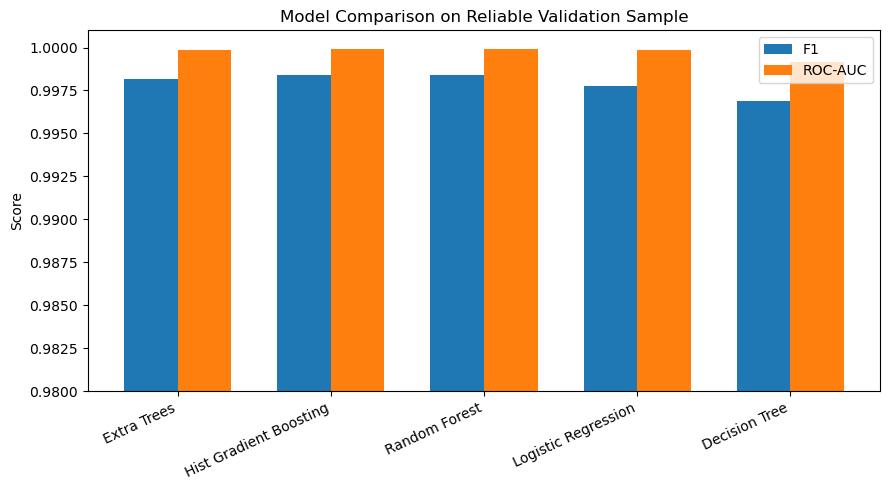

In [30]:
ModelPlotData=ModelResults.copy()

plt.figure(figsize=(9,5))

x=np.arange(len(ModelPlotData["Model"]))
width=0.35

plt.bar(x-width/2,ModelPlotData["F1"],width,label="F1")
plt.bar(x+width/2,ModelPlotData["ROC-AUC"],width,label="ROC-AUC")

plt.xticks(x,ModelPlotData["Model"],rotation=25,ha="right")
plt.ylabel("Score")
plt.title("Model Comparison on Reliable Validation Sample")
plt.ylim(0.98,1.001)
plt.legend()
plt.tight_layout()
plt.show()

### The model comparison results show that all selected algorithms achieved very strong performance on the reliable labeled dataset, with ROC-AUC values close to 1.00. Extra Trees produced the best business-oriented result because it achieved zero false positives while still keeping very high recall and F1-score.

### Since the project priority is to avoid incorrectly labeling ordinary consumers as business-like users, Extra Trees is the strongest candidate for the final model at the default threshold of 0.50. Hist Gradient Boosting and Random Forest also performed very well, but they produced several false positives, which makes them slightly less suitable for the selected business priority.

# 10. Final Model Selection & Probability Threshold Review

Among the compared classifiers, Extra Trees is selected as the final model.

Although Random Forest and Hist Gradient Boosting achieve slightly higher F1
scores, Extra Trees produces zero false positive classifications on the reliable
validation sample while maintaining very high recall and ROC-AUC.

The predicted probability is first used as a hidden business potential score.
Then, together with the number of strong business-like signals, it is converted
into the final binary prediction.

In [31]:
ExtraTreesParamGrid = {
    "n_estimators": [200, 300],
    "max_depth": [10, 14, None],
    "min_samples_leaf": [3, 5, 10],
    "max_features": ["sqrt", None]
}

cv_light = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

ExtraTreesSearch = RandomizedSearchCV(
    estimator=ExtraTreesClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ),
    param_distributions=ExtraTreesParamGrid,
    n_iter=10,
    scoring="f1",
    cv=cv_light,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

ExtraTreesSearch.fit(XTrain, yTrain)

print("Best score:", ExtraTreesSearch.best_score_)
print("Best params:")
display(ExtraTreesSearch.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best score: 0.9981643937986543
Best params:


{'n_estimators': 200,
 'min_samples_leaf': 3,
 'max_features': None,
 'max_depth': None}

In [32]:
BestExtraTrees=ExtraTreesSearch.best_estimator_

BestTestProbability=BestExtraTrees.predict_proba(XTest)[:, 1]
BestTestPrediction=(BestTestProbability >= 0.50).astype(int)

print("Accuracy:", accuracy_score(yTest, BestTestPrediction))
print("Precision:", precision_score(yTest, BestTestPrediction, zero_division=0))
print("Recall:", recall_score(yTest, BestTestPrediction))
print("F1:", f1_score(yTest, BestTestPrediction))
print("ROC-AUC:", roc_auc_score(yTest, BestTestProbability))

Accuracy: 0.9990083994400373
Precision: 0.999198557403326
Recall: 0.9974
F1: 0.9982984686217596
ROC-AUC: 0.9996450963438736


In [33]:
SelectedModelName="Extra Trees"
SelectedModel=BestExtraTrees

SelectedTestProbability=BestExtraTrees.predict_proba(XTest)[:,1]

ThresholdResults=[]
for threshold in [0.50,0.60,0.70,0.80,0.90,0.95,0.99]:
    prediction=(SelectedTestProbability>=threshold).astype(int)

    tn,fp,fn,tp=confusion_matrix(yTest,prediction).ravel()

    ThresholdResults.append({
        "Threshold":threshold,
        "Accuracy":accuracy_score(yTest,prediction),
        "Precision":precision_score(yTest,prediction,zero_division=0),
        "Recall":recall_score(yTest,prediction),
        "F1":f1_score(yTest,prediction),
        "FalsePositive":fp,
        "FalseNegative":fn,
        "TruePositive":tp,
        "TrueNegative":tn
    })

ThresholdResults=pd.DataFrame(ThresholdResults)

FormattedThresholdResults=ThresholdResults.copy()

for column in ["Accuracy","Precision","Recall","F1"]:
    FormattedThresholdResults[column]=(
        FormattedThresholdResults[column].map("{:.4f}".format)
    )

FormattedThresholdResults

,Threshold,Accuracy,Precision,Recall,F1,FalsePositive,FalseNegative,TruePositive,TrueNegative
0,0.5000,0.9990,0.9992,0.9974,0.9983,8,26,9974,24280
1,0.6000,0.9991,0.9996,0.9974,0.9985,4,26,9974,24284
2,0.7000,0.9991,0.9998,0.9971,0.9984,2,29,9971,24286
3,0.8000,0.9990,0.9999,0.9967,0.9983,1,33,9967,24287
4,0.9000,0.9989,1.0000,0.9963,0.9981,0,37,9963,24288
5,0.9500,0.9987,1.0000,0.9954,0.9977,0,46,9954,24288
6,0.9900,0.9983,1.0000,0.9941,0.9970,0,59,9941,24288


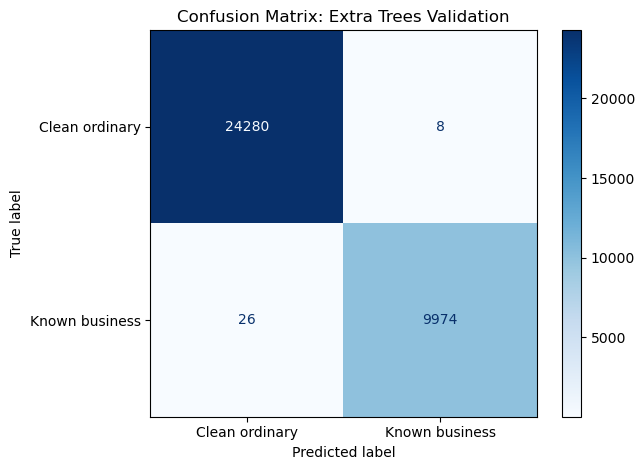

In [34]:
ValidationThreshold=0.50
ValidationPrediction=(SelectedTestProbability>=ValidationThreshold).astype(int)

cm=confusion_matrix(yTest,ValidationPrediction)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Clean ordinary","Known business"]
).plot(cmap="Blues",values_format="d")

plt.title("Confusion Matrix: Extra Trees Validation")
plt.tight_layout()
plt.show()

### For the selected Extra Trees model, thresholds above 0.50 preserve very high precision on the reliable validation sample.

### However, the final solution does not rely on a single binary threshold. The probability score is combined with the number of strong business-like signals to assign each card to Low potential, Medium potential, or High potential.

### In the final segmentation, 0.50 is used as an initial elevated-probability level, while 0.90 is used as the high-confidence probability level.

# 11. Model-Based Scoring of Uncertain Consumers

The selected Extra Trees model is trained on the complete reliable labeled dataset and applied to previously unlabeled uncertain consumer cards.

The model first estimates the hidden business probability for each uncertain consumer card. Then cards are assigned to small supporting potential groups: Low potential, Medium potential, or High potential.

These groups are used only as an interpretation layer. The final model output is converted into a binary prediction:

- 0: ordinary consumer or insufficient hidden-business evidence;
- 1: high-confidence hidden business candidate.

In this step, we use the best-performing model to score uncertain consumer cards that were excluded from the clean ordinary consumer sample. Each card receives a hidden business probability, and then a potential level is assigned using both the model score and the number of confirmed strong business-like signals:

In [35]:
FinalModel=ExtraTreesClassifier(
    **ExtraTreesSearch.best_params_,
    random_state=42,
    n_jobs=-1
)

FinalModel.fit(X,y)

UncertainX=UncertainConsumers[ModelFeatures].astype(float)

UncertainConsumers["HiddenBusinessProbability"]=FinalModel.predict_proba(UncertainX)[:,1]

UncertainConsumers["PotentialLevel"]=np.select(
    [
        (UncertainConsumers["HiddenBusinessProbability"]>=0.90)&
        (UncertainConsumers["StrongBusinessSignalCount"]>=3),
        (UncertainConsumers["HiddenBusinessProbability"]>=0.50)|
        (UncertainConsumers["StrongBusinessSignalCount"]>=2)
    ],
    [
        "High potential",
        "Medium potential"
    ],
    default="Low potential"
)

UncertainConsumers["FinalPrediction"]=(
    UncertainConsumers["PotentialLevel"]=="High potential"
).astype(int)

print("Uncertain consumer cards:",len(UncertainConsumers))

PotentialSummaryUncertain=(
    UncertainConsumers["PotentialLevel"]
    .value_counts()
    .reset_index()
)

PotentialSummaryUncertain.columns=["PotentialLevel","Cards"]

PotentialSummaryUncertain["Share"]=(
    PotentialSummaryUncertain["Cards"]/len(UncertainConsumers)
).map("{:.2%}".format)

display(PotentialSummaryUncertain)

Uncertain consumer cards: 19281


,PotentialLevel,Cards,Share
0,High potential,11540,59.85%
1,Low potential,5202,26.98%
2,Medium potential,2539,13.17%


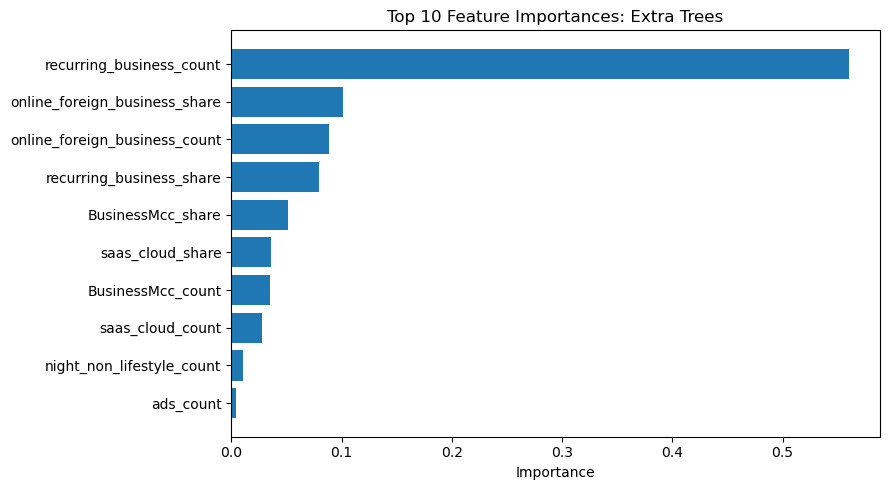

In [36]:
FeatureImportance=(
    pd.DataFrame({
        "Feature":ModelFeatures,
        "Importance":FinalModel.feature_importances_
    })
    .sort_values("Importance",ascending=False)
    .head(10)
)

plt.figure(figsize=(9,5))
plt.barh(FeatureImportance["Feature"],FeatureImportance["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Top 10 Feature Importances: Extra Trees")
plt.tight_layout()
plt.show()

In this step, we combine clean ordinary consumers and uncertain consumers into one final consumer prediction table. Clean ordinary consumers are labeled as low potential based on the proxy rule, while uncertain consumers are scored using the Extra Trees model and assigned a prediction basis for transparency:

In [37]:
CleanOrdinaryOutput=CleanOrdinaryConsumers[["card_number"]].copy()

CleanOrdinaryOutput["HiddenBusinessProbability"]=0.0
CleanOrdinaryOutput["StrongBusinessSignalCount"]=0
CleanOrdinaryOutput["PotentialLevel"]="Low potential"
CleanOrdinaryOutput["FinalPrediction"]=0
CleanOrdinaryOutput["PredictionBasis"]="Clean ordinary proxy rule"

UncertainOutput=UncertainConsumers[
    [
        "card_number",
        "HiddenBusinessProbability",
        "StrongBusinessSignalCount",
        "PotentialLevel",
        "FinalPrediction"
    ]
].copy()

UncertainOutput["PredictionBasis"]="Extra Trees score + potential level rule"

FinalConsumerPredictions=pd.concat(
    [CleanOrdinaryOutput,UncertainOutput],
    ignore_index=True
)

assert len(FinalConsumerPredictions)==len(ConsumerCardFeatures)
assert FinalConsumerPredictions["card_number"].nunique()==len(ConsumerCardFeatures)

FinalConsumerPredictions.head()

,card_number,HiddenBusinessProbability,StrongBusinessSignalCount,PotentialLevel,FinalPrediction,PredictionBasis
0,5100610005962109,0.0000,0,Low potential,0,Clean ordinary proxy rule
1,5100610007285137,0.0000,0,Low potential,0,Clean ordinary proxy rule
2,5100610011916156,0.0000,0,Low potential,0,Clean ordinary proxy rule
3,5100610012043588,0.0000,0,Low potential,0,Clean ordinary proxy rule
4,5100610013038587,0.0000,0,Low potential,0,Clean ordinary proxy rule


### The uncertain consumer scoring stage identified **19,281 consumer cards** with at least one strong business-like signal. Among them, **11,540 cards, or 59.85%**, were classified as high potential, meaning they have both strong model-based hidden business probability and multiple confirmed business-like behavioral signals.

### Another **2,539 uncertain consumers, or 13.17%**, were assigned medium potential, while **5,202 cards, or 26.98%**, remained low potential after model scoring. This shows that not all consumers with business-like signals should be treated the same: the final segmentation separates stronger hidden-business candidates from weaker or less consistent cases.

### The final consumer prediction table combines both groups into one complete output. Clean ordinary consumers are assigned low potential by rule, while uncertain consumers receive Extra Trees model scores, potential levels, and final predictions, making the result suitable for reporting, segmentation, and further business review.


# 12. Final Binary Prediction Summary

The final consumer portfolio is summarized by binary model output.

The potential groups are retained only as a supporting explanation, while the final decision variable is `FinalPrediction`.

Only cards from the High potential group are assigned to class 1. Low and Medium potential cards remain class 0.

In this step, we summarize the final binary prediction results for all consumer cards. The table shows how many cards were classified as ordinary consumers and how many were classified as potential hidden business cards:

In [38]:
FinalPredictionSummary=(
    FinalConsumerPredictions["FinalPrediction"]
    .value_counts()
    .reset_index()
)
FinalPredictionSummary.columns=["FinalPrediction","Cards"]
FinalPredictionSummary["Share"]=(
    FinalPredictionSummary["Cards"]/len(FinalConsumerPredictions)
).map("{:.2%}".format)
FinalPredictionSummary

,FinalPrediction,Cards,Share
0,0,68460,85.58%
1,1,11540,14.42%


In this step, we summarize the final potential level distribution across all consumer cards. This helps understand how many consumers fall into low, medium, and high potential groups after combining rule-based filtering and model-based scoring:

In [39]:
PotentialLevelSummary=(
    FinalConsumerPredictions["PotentialLevel"]
    .value_counts()
    .reset_index()
)

PotentialLevelSummary.columns=["PotentialLevel","Cards"]

PotentialLevelSummary["Share"]=(
    PotentialLevelSummary["Cards"]/len(FinalConsumerPredictions)
).map("{:.2%}".format)

PotentialLevelSummary

,PotentialLevel,Cards,Share
0,Low potential,65921,82.40%
1,High potential,11540,14.42%
2,Medium potential,2539,3.17%


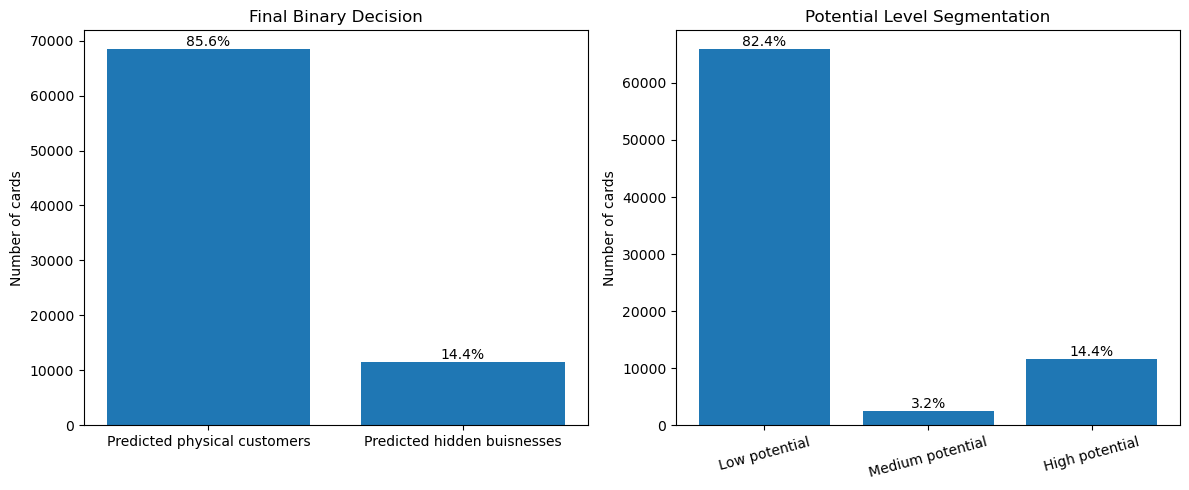

In [40]:
BinaryPlotData=FinalPredictionSummary.copy()
BinaryPlotData["Class"]=BinaryPlotData["FinalPrediction"].map({
    0:"Predicted physical customers",
    1:"Predicted hidden buisnesses"
})
BinaryPlotData["ShareValue"]=BinaryPlotData["Cards"]/BinaryPlotData["Cards"].sum()

PotentialPlotData=PotentialLevelSummary.copy()
PotentialOrder=["Low potential","Medium potential","High potential"]
PotentialPlotData["PotentialLevel"]=pd.Categorical(
    PotentialPlotData["PotentialLevel"],
    categories=PotentialOrder,
    ordered=True
)
PotentialPlotData=PotentialPlotData.sort_values("PotentialLevel")
PotentialPlotData["ShareValue"]=PotentialPlotData["Cards"]/PotentialPlotData["Cards"].sum()

fig,axes=plt.subplots(1,2,figsize=(12,5))

bars1=axes[0].bar(BinaryPlotData["Class"],BinaryPlotData["Cards"])
axes[0].set_title("Final Binary Decision")
axes[0].set_ylabel("Number of cards")

for bar,share in zip(bars1,BinaryPlotData["ShareValue"]):
    axes[0].text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{share:.1%}",
        ha="center",
        va="bottom"
    )

bars2=axes[1].bar(PotentialPlotData["PotentialLevel"],PotentialPlotData["Cards"])
axes[1].set_title("Potential Level Segmentation")
axes[1].set_ylabel("Number of cards")
axes[1].tick_params(axis="x",rotation=15)

for bar,share in zip(bars2,PotentialPlotData["ShareValue"]):
    axes[1].text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f"{share:.1%}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### The final prediction summary shows that **11,540 consumer cards, or 14.42% of the full consumer portfolio**, were classified as potential hidden business cards. The remaining **68,460 cards, or 85.58%**, were not classified as hidden business activity.

### The potential level summary gives a more detailed segmentation: **65,921 cards, or 82.40%**, were assigned low potential, **2,539 cards, or 3.17%**, were assigned medium potential, and **11,540 cards, or 14.42%**, were assigned high potential. This means the model does not simply flag every uncertain card, but separates the consumer portfolio into clear risk-based groups.

### Overall, this block provides the final business-facing output of the project: a full consumer segmentation with binary hidden-business predictions and potential levels for further review, reporting, or targeted business actions.


# 13. Final Output

The final output contains one row per consumer card.

The key output column is `FinalPrediction`, where 0 means ordinary consumer or insufficient hidden-business evidence, and 1 means high-confidence hidden business candidate.

The probability score and potential level are kept as supporting interpretation fields.

In [41]:
FinalConsumerPredictions.to_parquet(
    "final_consumer_hidden_business_predictions.parquet",
    index=False
)

FinalConsumerPredictions.to_csv(
    "final_consumer_hidden_business_predictions.csv",
    index=False
)

print("Final prediction files saved successfully.")

Final prediction files saved successfully.


# Additional INFO for Analysis: Business- Segmentation

In [44]:
FinalStrictCandidates=UncertainConsumers[
    UncertainConsumers["FinalPrediction"]==1
].copy()

candidates=FinalStrictCandidates.copy()
total=len(candidates)

def assign_activity(row):
    ads=row["ads_count"]>=2 or row["ads_share"]>=0.05
    saas=row["saas_cloud_count"]>=2 or row["saas_cloud_share"]>=0.08
    it=row["it_software_count"]>=2 or row["it_software_share"]>=0.05 or row["mixed_household_it"]
    recurring=row["recurring_business_count"]>=2 or row["recurring_business_share"]>=0.05
    foreign_online=row["online_foreign_business_count"]>=2 or row["online_foreign_business_share"]>=0.05
    household_ads=row["mixed_household_ads"]
    household_it=row["mixed_household_it"]
    business_share=row["BusinessMcc_share"]

    if ads and saas and foreign_online:
        return "Online commerce / digital entrepreneur"

    if ads and household_ads:
        return "Small online seller / social commerce"

    if it and saas and recurring:
        return "IT / software / freelance digital services"

    if ads and business_share>=0.20:
        return "Marketing / advertising-related business"

    if household_it or household_ads:
        return "Small retail / mixed household-business trade"

    if foreign_online and recurring:
        return "Subscription-based online business"

    if saas or it:
        return "Digital services / online professional activity"

    if recurring:
        return "Service business with recurring tools/payments"

    return "Other mixed small business activity"


if total==0:
    ActivitySummary=pd.DataFrame(
        columns=["Inferred business activity","Cards","Share"]
    )
else:
    candidates["InferredBusinessActivity"]=candidates.apply(
        assign_activity,
        axis=1
    )

    ActivitySummary=(
        candidates["InferredBusinessActivity"]
        .value_counts()
        .reset_index()
    )

    ActivitySummary.columns=["Inferred business activity","Cards"]

    ActivitySummary["Share"]=(
        ActivitySummary["Cards"]/total
    ).map("{:.2%}".format)

display(ActivitySummary)

,Inferred business activity,Cards,Share
0,Online commerce / digital entrepreneur,4635,40.16%
1,Subscription-based online business,2975,25.78%
2,IT / software / freelance digital services,1970,17.07%
3,Small online seller / social commerce,1883,16.32%
4,Digital services / online professional activity,47,0.41%
5,Small retail / mixed household-business trade,29,0.25%
6,Marketing / advertising-related business,1,0.01%
